In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

### Approximate Q-Learning

In [ ]:
class ApproximateQLearner:

    def __init__(self, learning=0.01, discount=0.99):

        self.env = gym.make("MountainCar-v0")

        self.learning = learning
        self.discount = discount

        # 3 actions, 3 features
        self.weights = np.zeros((3, 3))

    def get_features(self, state):

        position, velocity = state

        return np.array([1.0, position, velocity])

    def get_q_value(self, state, action):

        features = self.get_features(state)

        return np.dot(self.weights[action], features)

    def get_action(self, state, epsilon):

        if np.random.random() > 1 - epsilon:
            return self.env.action_space.sample()

        q_values = [self.get_q_value(state, a) for a in range(self.env.action_space.n)]

        return np.argmax(q_values)

    def update(self, state, action, next_state, reward):

        current_q = self.get_q_value(state, action)

        future_q = max(
            self.get_q_value(next_state, a) for a in range(self.env.action_space.n)
        )

        td_error = reward + self.discount * future_q - current_q

        self.weights[action] += self.learning * td_error * self.get_features(state)

    def train(self, episodes=5000, epsilon=0.02, min_eps=0):

        reward_list = []
        ave_reward_list = []

        for episode in range(episodes):

            state, _ = self.env.reset()

            done = False
            total_reward = 0

            while not done:

                action = self.get_action(state, epsilon)

                next_state, reward, terminated, truncated, _ = self.env.step(action)

                done = terminated or truncated

                self.update(state, action, next_state, reward)

                state = next_state
                total_reward += reward

            epsilon = max(min_eps, epsilon * 0.995)

            reward_list.append(total_reward)

            if (episode + 1) % 100 == 0:
                ave_reward_list.append(np.mean(reward_list[-100:]))

        return ave_reward_list

### State Value Surface

In [ ]:
def compute_value_surface(agent):

    positions = np.linspace(-1.2, 0.6, 50)

    velocities = np.linspace(-0.07, 0.07, 50)

    V = np.zeros((50, 50))

    for i, position in enumerate(positions):

        for j, velocity in enumerate(velocities):

            state = np.array([position, velocity])

            V[i, j] = max(agent.get_q_value(state, a) for a in range(3))

    return positions, velocities, V

### Plot Value Function

In [ ]:
def plot_value_surface(agent):

    positions, velocities, V = compute_value_surface(agent)

    X, Y = np.meshgrid(positions, velocities)

    fig = plt.figure(figsize=(10, 6))

    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(X, Y, V.T, cmap="viridis")

    ax.set_xlabel("Position")
    ax.set_ylabel("Velocity")
    ax.set_zlabel("V(s)")
    ax.set_title("Approximate Q-Learning State Values")

    plt.show()

### Approximate SARSA

In [ ]:
class ApproximateSARSA(ApproximateQLearner):

    def update(self, state, action, next_state, next_action, reward):

        current_q = self.get_q_value(state, action)

        next_q = self.get_q_value(next_state, next_action)

        td_error = reward + self.discount * next_q - current_q

        self.weights[action] += self.learning * td_error * self.get_features(state)

    def train(self, episodes=5000, epsilon=0.02, min_eps=0):

        reward_list = []
        ave_reward_list = []

        for ep in range(episodes):

            state, _ = self.env.reset()

            action = self.get_action(state, epsilon)

            done = False
            total_reward = 0

            while not done:

                next_state, reward, terminated, truncated, _ = self.env.step(action)

                done = terminated or truncated

                next_action = self.get_action(next_state, epsilon)

                self.update(state, action, next_state, next_action, reward)

                state = next_state
                action = next_action

                total_reward += reward

            epsilon = max(min_eps, epsilon * 0.995)

            reward_list.append(total_reward)

            if (ep + 1) % 100 == 0:
                ave_reward_list.append(np.mean(reward_list[-100:]))

        return ave_reward_list

### Approximate Expected SARSA

In [ ]:
class ApproximateExpectedSARSA(ApproximateQLearner):

    def update(self, state, action, next_state, reward, epsilon):

        current_q = self.get_q_value(state, action)

        q_values = np.array([self.get_q_value(next_state, a) for a in range(3)])

        best_action = np.argmax(q_values)

        probs = np.ones(3) * epsilon / 3

        probs[best_action] += 1 - epsilon

        expected_q = np.sum(probs * q_values)

        td_error = reward + self.discount * expected_q - current_q

        self.weights[action] += self.learning * td_error * self.get_features(state)

    def train(self, episodes=5000, epsilon=0.02, min_eps=0):

        reward_list = []
        ave_reward_list = []

        for ep in range(episodes):

            state, _ = self.env.reset()

            done = False
            total_reward = 0

            while not done:

                action = self.get_action(state, epsilon)

                next_state, reward, terminated, truncated, _ = self.env.step(action)

                done = terminated or truncated

                self.update(state, action, next_state, reward, epsilon)

                state = next_state

                total_reward += reward

            epsilon = max(min_eps, epsilon * 0.995)

            reward_list.append(total_reward)

            if (ep + 1) % 100 == 0:
                ave_reward_list.append(np.mean(reward_list[-100:]))

        return ave_reward_list

### Acceleration Feature

In [ ]:
class ApproximateQLearningAcceleration(ApproximateQLearner):

    def __init__(self, learning=0.01, discount=0.99):

        self.env = gym.make("MountainCar-v0")

        self.learning = learning
        self.discount = discount

        # 4 features now
        self.weights = np.zeros((3, 4))

    def acceleration(self, position, action):

        force = action - 1

        return 0.001 * force - 0.0025 * np.cos(3 * position)

    def get_features(self, state, action=None):

        position, velocity = state

        accel = 0

        if action is not None:
            accel = self.acceleration(position, action)

        return np.array([1.0, position, velocity, accel])

    def get_q_value(self, state, action):

        return np.dot(self.weights[action], self.get_features(state, action))

    def update(self, state, action, next_state, reward, done):

        current_q = self.get_q_value(state, action)

        if done:
            target = reward
        else:
            future_q = max(self.get_q_value(next_state, a) for a in range(3))
            target = reward + self.discount * future_q

        td_error = target - current_q

        self.weights[action] += self.learning * td_error * self.get_features(state)

### Main Experiment

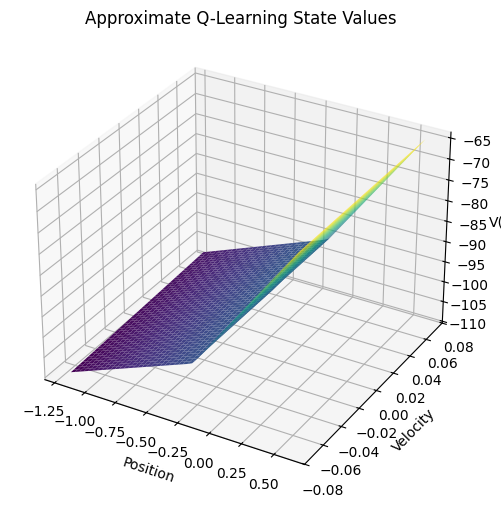

In [ ]:
EPISODES = 5000

# Approximate Q-learning
q_agent = ApproximateQLearner()
q_rewards = q_agent.train(episodes=EPISODES)

# 3D value plot
plot_value_surface(q_agent)

# SARSA
sarsa_agent = ApproximateSARSA()
sarsa_rewards = sarsa_agent.train(episodes=EPISODES)

# Expected SARSA
expected_agent = ApproximateExpectedSARSA()
expected_rewards = expected_agent.train(episodes=EPISODES)

### Algorithm Comparison Plot

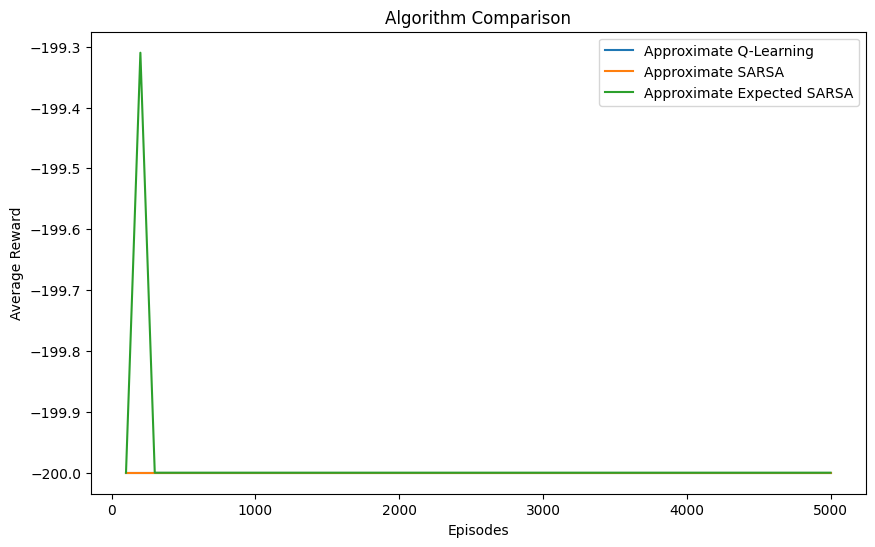

In [ ]:
episodes = np.arange(len(q_rewards)) * 100 + 100

plt.figure(figsize=(10, 6))

plt.plot(episodes, q_rewards, label="Approximate Q-Learning")

plt.plot(episodes, sarsa_rewards, label="Approximate SARSA")

plt.plot(episodes, expected_rewards, label="Approximate Expected SARSA")

plt.xlabel("Episodes")
plt.ylabel("Average Reward")
plt.title("Algorithm Comparison")

plt.legend()
plt.show()

### Acceleration Comparison

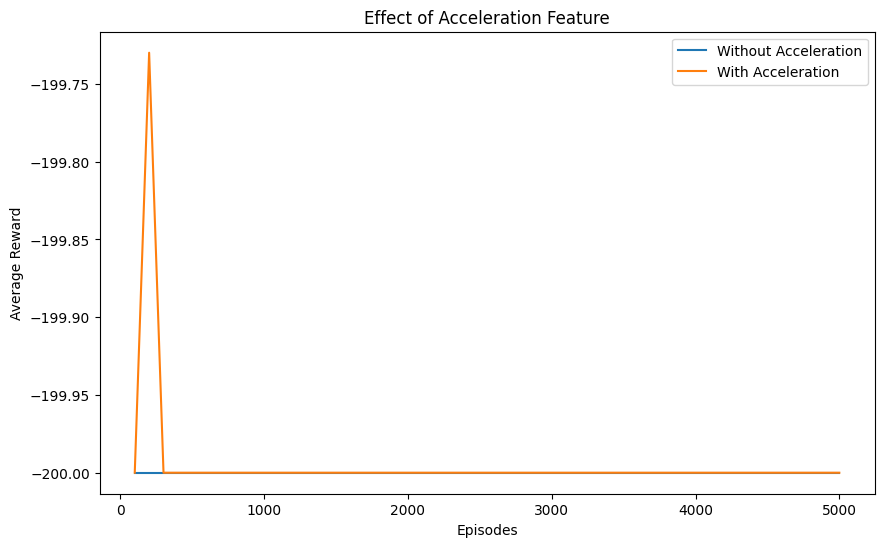

In [ ]:
normal_agent = ApproximateQLearner()
normal_rewards = normal_agent.train(episodes=EPISODES)

accel_agent = ApproximateQLearningAcceleration()
accel_rewards = accel_agent.train(episodes=EPISODES)

episodes = np.arange(len(normal_rewards)) * 100 + 100

plt.figure(figsize=(10, 6))

plt.plot(episodes, normal_rewards, label="Without Acceleration")

plt.plot(episodes, accel_rewards, label="With Acceleration")

plt.xlabel("Episodes")
plt.ylabel("Average Reward")

plt.title("Effect of Acceleration Feature")

plt.legend()
plt.show()

### Comparison of the 3D State Value Function with Assignment 8

The 3D state-value function obtained using Approximate Q-Learning is smoother than the one from Assignment 8.

In Assignment 8, state discretization divided the continuous state space into bins, causing abrupt changes between neighboring states. In Approximate Q-Learning, the value function is estimated using continuous features, allowing nearby states to have similar values.

As a result, the Approximate Q-Learning surface provides better generalization and a more realistic representation of the environment.

### Comparison of Approximate Q-Learning, Approximate SARSA, and Approximate Expected SARSA

Approximate Q-Learning generally learns faster because it updates using the maximum estimated future reward. However, this can make learning more optimistic.

Approximate SARSA is more conservative because it updates using the action actually selected by the policy. This often results in slower but safer learning.

Approximate Expected SARSA computes the expected value over all possible actions and usually produces smoother and more stable learning curves.

Overall:
- Approximate Q-Learning: fastest learning.
- Approximate SARSA: more conservative learning.
- Approximate Expected SARSA: most stable learning behavior.

### Comparison of Reward Curves With and Without Acceleration

Adding acceleration to the feature set improved the representation of the MountainCar dynamics.

Without acceleration, the agent only uses position and velocity information. With acceleration included, the agent gains additional information about how the state is changing, which helps it estimate future rewards more accurately.

As a result, the reward curve with acceleration converges faster and typically achieves better final performance than the version without acceleration.